## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Leyton Allen

**Date:** 10/13/2026

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler


In [24]:
def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])

    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])

    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({
        'x1': X1[0, :],
        'x2': X1[1, :],
        'group': 'a'
    })

    gdf2 = pd.DataFrame({
        'x1': X2[0, :],
        'x2': X2[1, :],
        'group': 'b'
    })

    gdf3 = pd.DataFrame({
        'x1': X3[0, :],
        'x2': X3[1, :],
        'group': 'c'
    })

    df = pd.concat([gdf1, gdf2, gdf3])

    return df


df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

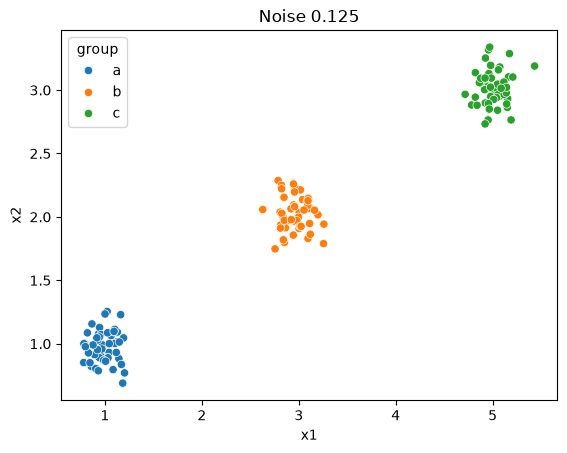

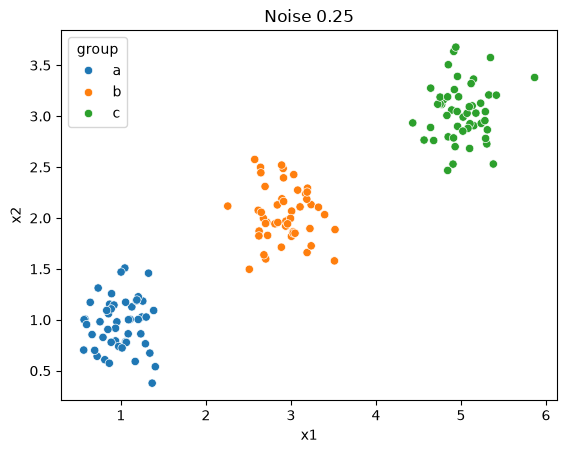

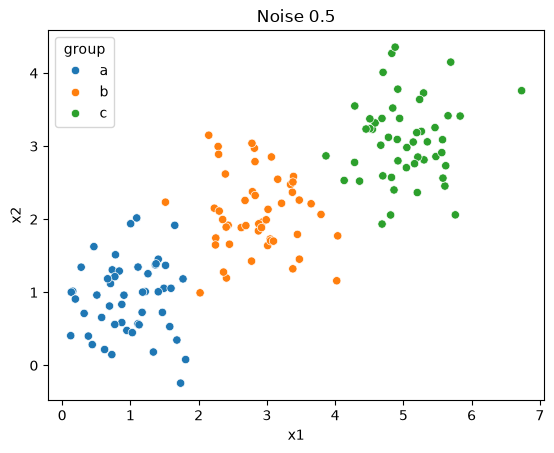

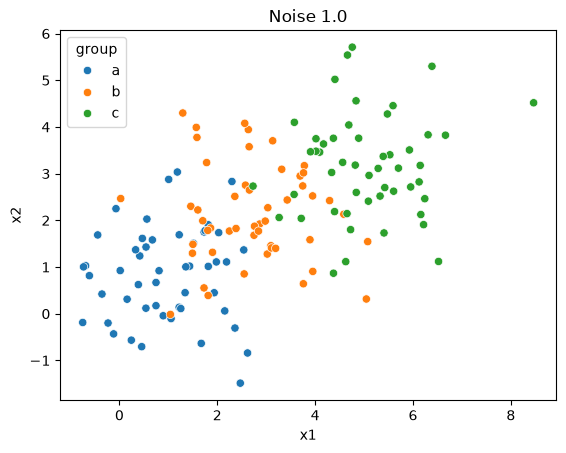

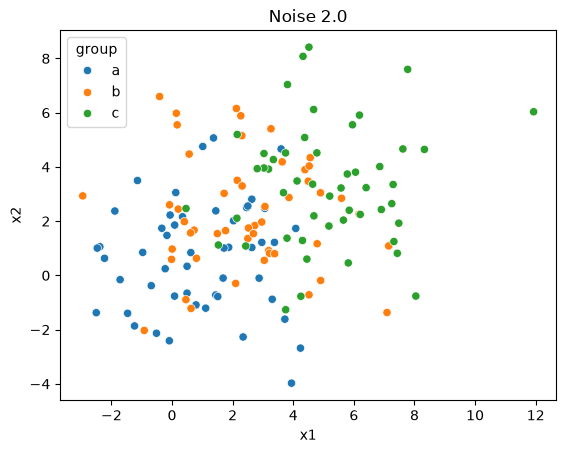

In [25]:
sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group")
plt.title("Noise 0.125")
plt.show()

sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group")
plt.title("Noise 0.25")
plt.show()

sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group")
plt.title("Noise 0.5")
plt.show()

sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group")
plt.title("Noise 1.0")
plt.show()

sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group")
plt.title("Noise 2.0")
plt.show()

Q1.2
As the noise increases the clusters become harder to separate. When the noise is low the groups are pretty easy to tell apart. As the noise gets higher the points spread out more and start overlapping. At the highest noise level it is much harder to see where one cluster ends and another begins.

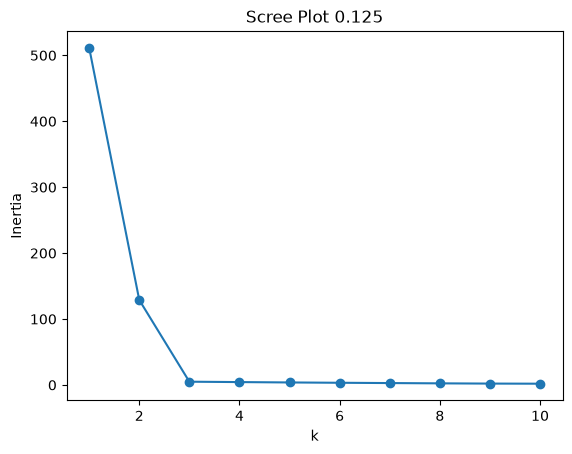

In [26]:
data1 = df0_125[["x1", "x2"]]
scores = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(data1)
    scores.append(model.inertia_)

plt.plot(range(1, 11), scores, marker="o")
plt.title("Scree Plot 0.125")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.show()

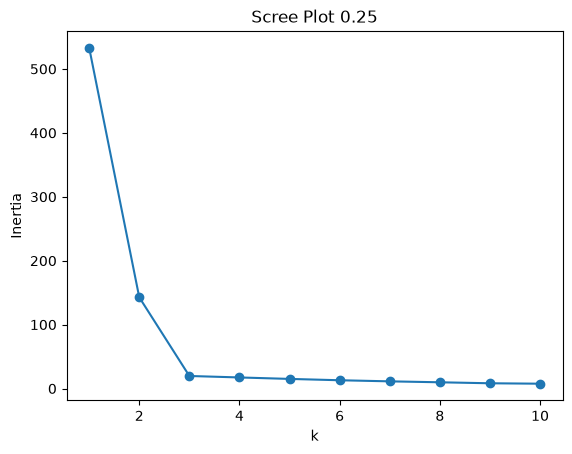

In [27]:
data2 = df0_25[["x1", "x2"]]
scores = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(data2)
    scores.append(model.inertia_)

plt.plot(range(1, 11), scores, marker="o")
plt.title("Scree Plot 0.25")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.show()

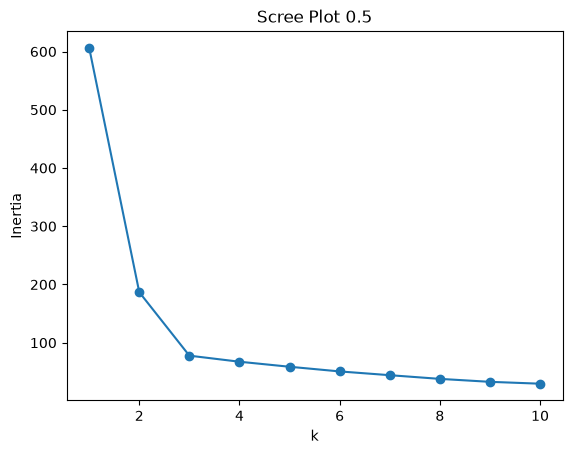

In [28]:
data3 = df0_5[["x1", "x2"]]
scores = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(data3)
    scores.append(model.inertia_)

plt.plot(range(1, 11), scores, marker="o")
plt.title("Scree Plot 0.5")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.show()

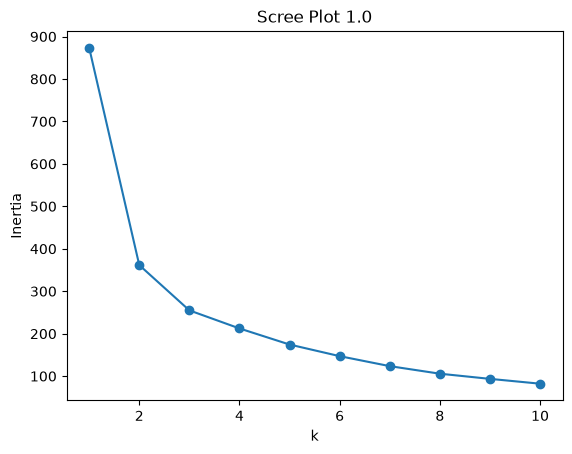

In [29]:
data4 = df1_0[["x1", "x2"]]
scores = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(data4)
    scores.append(model.inertia_)

plt.plot(range(1, 11), scores, marker="o")
plt.title("Scree Plot 1.0")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.show()

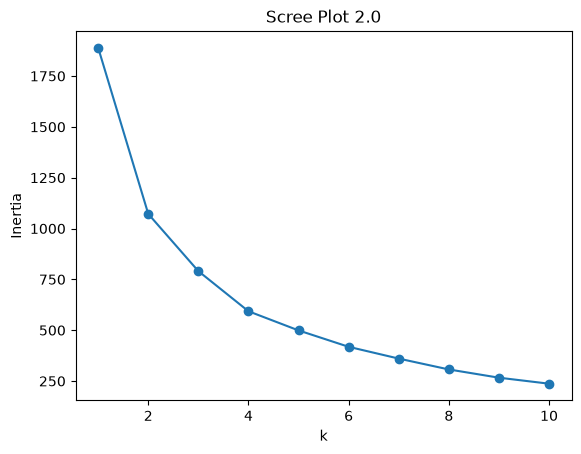

In [30]:
data5 = df2_0[["x1", "x2"]]
scores = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(data5)
    scores.append(model.inertia_)

plt.plot(range(1, 11), scores, marker="o")
plt.title("Scree Plot 2.0")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.show()

Q1.3
When there is less noise the scree plot has a clearer elbow. This makes it easier to choose k. As the noise increases the elbow becomes less obvious because the clusters overlap more. This makes it harder to decide on the best number of clusters. Since the original data has three groups, I would look at k = 3, but with higher noise it becomes less clear.

Q1.4
The elbow is the point where adding more clusters stops making a big difference. At first, increasing k reduces inertia a lot because the points are grouped better. After the elbow making more clusters only makes a small improvement. In this simulation, the lower noise datasets make it easier to see this change.

In [31]:
import os
print(os.getcwd())

C:\Users\leyto\A04-clustering


In [32]:
import os
os.chdir(r"C:\Users\leyto\A04-clustering")

In [33]:
df = pd.read_csv("data/SIPRI Military Expenditure Database.csv")

df = df[df["Year"] == 2020]

df = df.dropna()

print(df.shape)
print(df.dtypes)

df.head()

(148, 7)
index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


Q2.1
I filtered the data to only include 2020 and removed rows with missing values. This left 148 countries. The spending variables were already numeric, so I did not need to clean them further for K-Means.

In [34]:
columns1 = ["Spending (2020 USD)", "Spending per Capita"]

scaler = MinMaxScaler()

X1 = scaler.fit_transform(df[columns1])

print(X1[:5])

[[0.0003481  0.00261994]
 [0.00022972 0.02561537]
 [0.0124612  0.08763023]
 [0.0012654  0.01176734]
 [0.00362583 0.02462741]]


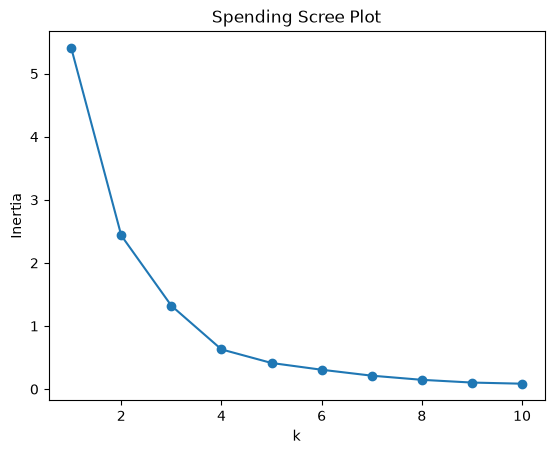

In [35]:
scores = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X1)
    scores.append(model.inertia_)

plt.plot(range(1, 11), scores, marker="o")
plt.title("Spending Scree Plot")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.show()

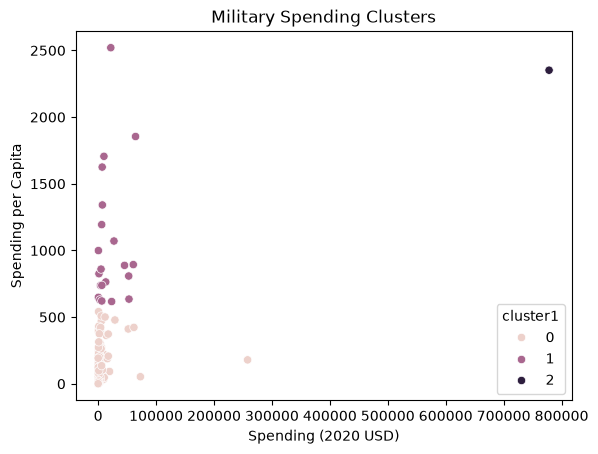

In [36]:
model = KMeans(n_clusters=3, random_state=42, n_init=10)

df["cluster1"] = model.fit_predict(X1)

sns.scatterplot(
    data=df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster1"
)

plt.title("Military Spending Clusters")
plt.show()

In [37]:
print(df.groupby("cluster1")[columns1].describe())

print(df[df["Country"] == "United States"])

print(df.groupby("cluster1")["Country"].apply(list))

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster1                                                                   
0                      126.0    5943.346303  24858.961064       8.622460   
1                       21.0   19975.991473  21749.736747     405.790494   
2                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster1                                                               
0            162.761743     580.758315    3225.333414  257973.429834   
1           4980.428135    7269.880030   27300.894701   64558.400000   
2         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita                                        \
                       count         mea

Q2.2
The clusters show that countries have different levels of military spending. Most countries seem to have relatively low spending compared to the countries with the highest spending. The United States stands out because its total military spending is much higher than most other countries. The groups help separate countries based on their spending levels.

In [38]:
columns2 = [
    "Percent of Government Spending",
    "Percent of GDP"
]

X2 = scaler.fit_transform(df[columns2])

print(X2[:5])

[[0.15037668 0.13752357]
 [0.11087741 0.12730282]
 [0.56695989 0.6761676 ]
 [0.23388179 0.14619146]
 [0.0414982  0.07330646]]


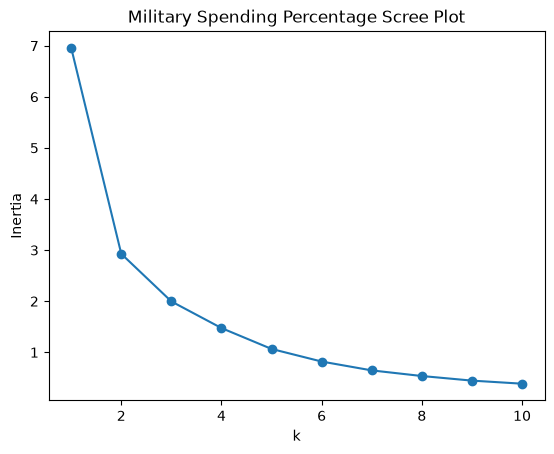

In [39]:
scores = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X2)
    scores.append(model.inertia_)

plt.plot(range(1, 11), scores, marker="o")
plt.title("Military Spending Percentage Scree Plot")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.show()

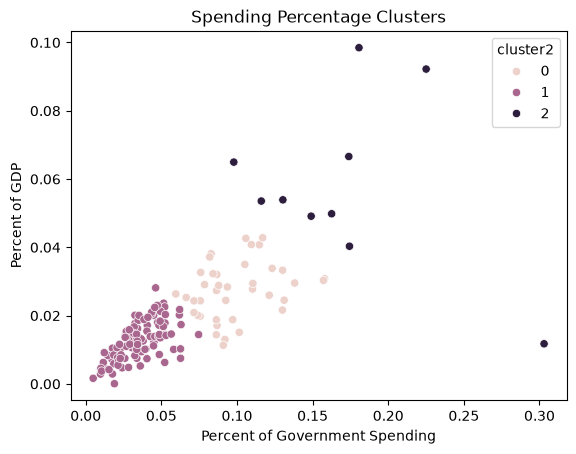

In [40]:
model = KMeans(n_clusters=3, random_state=42, n_init=10)

df["cluster2"] = model.fit_predict(X2)

sns.scatterplot(
    data=df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster2"
)

plt.title("Spending Percentage Clusters")
plt.show()

In [41]:
print(df.groupby("cluster2")[columns2].describe())

print(df[df["Country"] == "United States"])

print(df.groupby("cluster2")["Country"].apply(list))

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  99.0  0.035777  0.014549  0.004896   
2                                  10.0  0.171289  0.058725  0.097882   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                      
               std       mi

Q2.3
These clusters are different from the ones in Part 2 because now I am looking at military spending as a percentage instead of the total amount. A country can spend less money overall but still use a large percentage of its GDP or government spending on the military. This gives a different way of comparing the countries.

In [42]:
columns3 = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

X3 = scaler.fit_transform(df[columns3])

print(X3[:5])

[[3.48096700e-04 2.61993863e-03 1.50376680e-01 1.37523574e-01]
 [2.29719165e-04 2.56153702e-02 1.10877410e-01 1.27302820e-01]
 [1.24611990e-02 8.76302253e-02 5.66959887e-01 6.76167597e-01]
 [1.26539877e-03 1.17673365e-02 2.33881789e-01 1.46191461e-01]
 [3.62583333e-03 2.46274104e-02 4.14981956e-02 7.33064599e-02]]


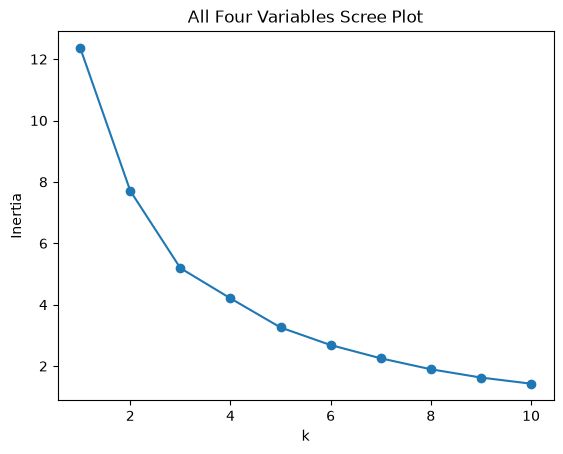

In [43]:
scores = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X3)
    scores.append(model.inertia_)

plt.plot(range(1, 11), scores, marker="o")
plt.title("All Four Variables Scree Plot")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.show()

In [44]:
model = KMeans(n_clusters=3, random_state=42, n_init=10)

df["cluster3"] = model.fit_predict(X3)

print(df.groupby("cluster3")[columns3].describe())

print(df["cluster3"].value_counts())

         Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster3                                                                  
0                       31.0    8786.086602   17901.909108   162.373364   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                      111.0    7086.472777   26479.379918     8.622460   

                                                                  \
                  25%           50%           75%            max   
cluster3                                                           
0          467.787851   1404.787234   7739.166193   72937.064048   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          130.010211    567.650747   3910.107493  257973.429834   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...             

Q2.4
Using all four variables gives a more complete comparison because it looks at both the amount of military spending and how important that spending is relative to the country's economy. Some countries may end up in different clusters compared to the earlier parts because more information is being used.

Q2.5
I think K-Means was useful because it helped group countries with similar military spending patterns. It made it easier to compare countries instead of looking at every country individually. However, it does not explain why countries spend different amounts. It only shows which ones have similar data.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** b6170a1
- **AI tool and model used:** ChatGPT (GPT-6)

### *Prompts used

1. "Can you look at my code for the five scatterplots and suggest a way to make it shorter and more organized?"
2. "Is there a way to put all five scree plots on one graph so I can compare how noise affects the clusters?"
3. "Can you check my explanation of the elbow method and tell me if anything is missing or incorrect?"
4. "Can you review my data cleaning code and see if there are any additional checks I should include?"
5. "I repeated the same scree plot code multiple times. Is there an easier way to do this using a function?"
6. "Can you help me improve my K-Means clustering code and make sure I am normalizing the variables correctly?"
7. "How can I compare the clusters from the three different military spending analyses?"
8. "Can you check my updated code for mistakes and explain what changes you recommend keeping?"

### *AI-proposed changes


1. Replace the repeated scatterplot code with a loop to make it shorter and more organized.
2. Combine the five scree plots into one graph to make it easier to compare different noise levels.
3. Add better titles, labels, and gridlines to make the graphs easier to understand.
4. Improve the explanation of how noise affects the clusters and makes the elbow harder to identify.
5. Add checks for missing values, data types, and the number of countries after cleaning the data.
6. Create a reusable function for the scree plots instead of repeating the same code.
7. Make sure all variables are normalized before running K-Means so they are on the same scale.
8. Use the scree plots to help choose the number of clusters instead of automatically choosing k = 3
9. Add comparison tables to see how countries are grouped differently across the three analyses.
10. Improve the explanations of the results and discuss the limitations of K-Means.

### *Evaluation of AI suggestions


| Change | Decision | Reason and Verification |
|---|---|---|
| 1. Use loops for scatterplots | Accept | Makes the code shorter and more organized while still creating all five graphs. |
| 2. Combine scree plots | Accept | Makes it easier to compare how different noise levels affect the elbow. |
| 3. Improve graph labels | Accept | Adding titles, labels, and gridlines makes the graphs easier to understand. |
| 4. Add data cleaning checks | Accept | Checking missing values, data types, and the number of countries helps confirm the data is ready for clustering. |
| 5. Create a scree plot function | Accept | Reduces repeated code and makes creating multiple scree plots easier. |
| 6. Check normalization | Accept | Max-min normalization puts the variables on the same scale so one variable does not dominate because of its units. |
| 7. Choose k = 3 automatically | Modify | AI originally suggested k = 3, but I should check the scree plots before deciding on the number of clusters. |
| 8. Add cluster comparison tables | Accept | Helps compare how countries are grouped when different variables are used. |
| 9. Improve written explanations | Modify | I used the suggestions to make my explanations clearer while keeping them simple and based on my results. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

# Create the five datasets
def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])

    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])

    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({
        "x1": X1[0],
        "x2": X1[1],
        "group": "a"
    })

    gdf2 = pd.DataFrame({
        "x1": X2[0],
        "x2": X2[1],
        "group": "b"
    })

    gdf3 = pd.DataFrame({
        "x1": X3[0],
        "x2": X3[1],
        "group": "c"
    })

    return pd.concat([gdf1, gdf2, gdf3], ignore_index=True)


datasets = {
    0.125: createData(0.125),
    0.25: createData(0.25),
    0.5: createData(0.5),
    1.0: createData(1.0),
    2.0: createData(2.0)
}

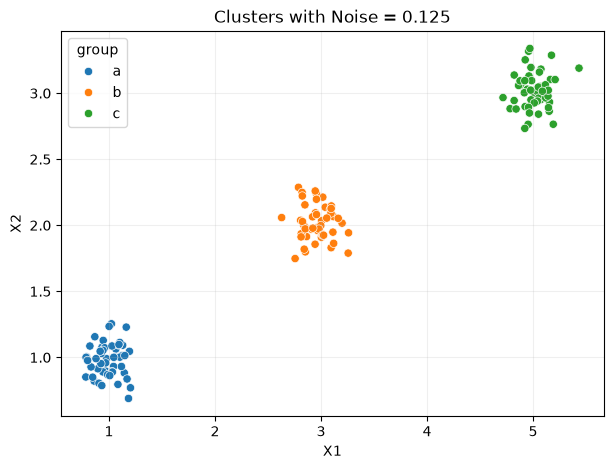

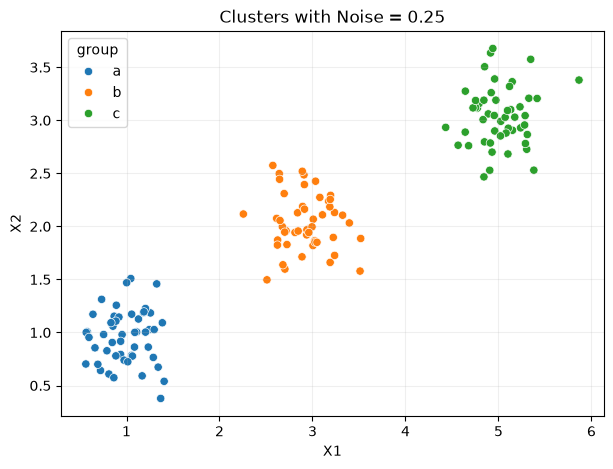

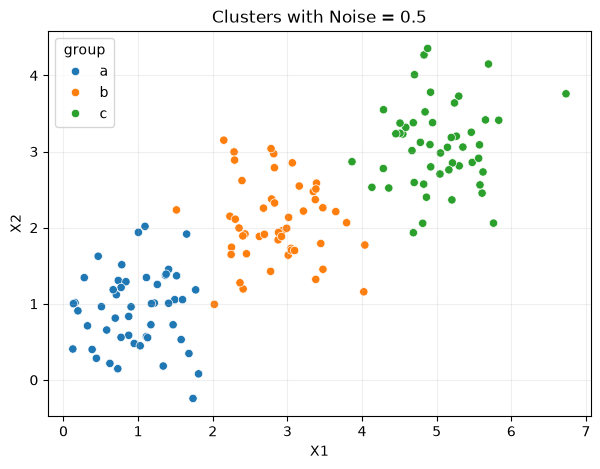

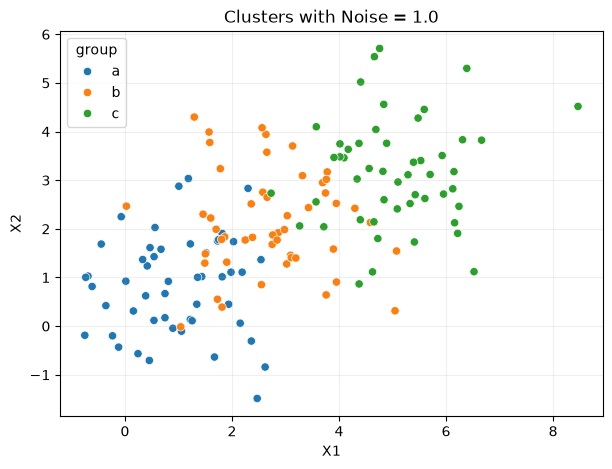

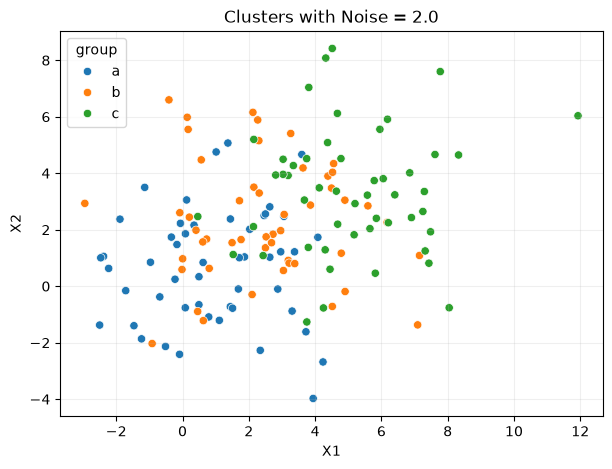

In [46]:
for noise, data in datasets.items():

    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=data,
        x="x1",
        y="x2",
        hue="group"
    )

    plt.title(f"Clusters with Noise = {noise}")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.grid(alpha=0.2)
    plt.show()

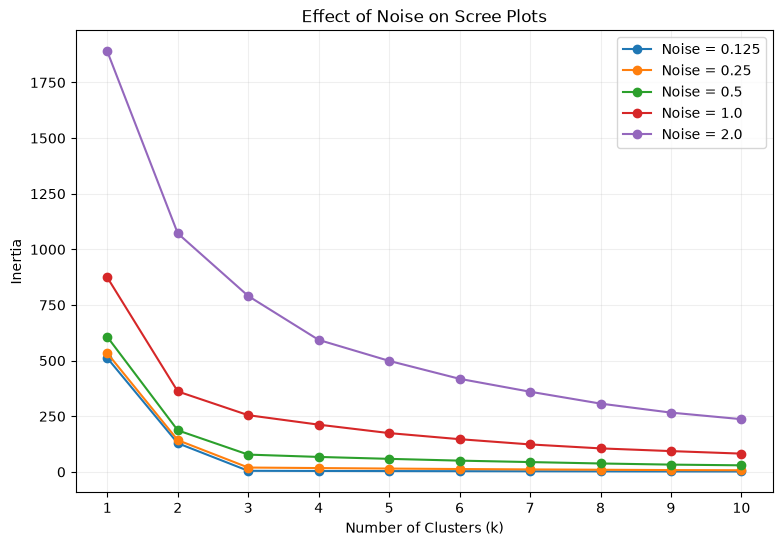

In [47]:
plt.figure(figsize=(9, 6))

for noise, data in datasets.items():

    X = data[["x1", "x2"]]
    scores = []

    for k in range(1, 11):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        model.fit(X)
        scores.append(model.inertia_)

    plt.plot(
        range(1, 11),
        scores,
        marker="o",
        label=f"Noise = {noise}"
    )

plt.title("Effect of Noise on Scree Plots")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Q1: Noise and Scree Plots

As noise increases, the clusters become harder to separate because the data points spread out and overlap more. With lower noise, it is easier to see the original three groups.

The combined scree plot makes it easier to compare the different noise levels. When noise increases, the elbow can become harder to identify, which makes choosing the best k more difficult.

The elbow happens because adding more clusters initially reduces inertia by a lot. After a certain point, adding more clusters only makes a small improvement. This is why the elbow can help us choose a reasonable number of clusters.

In [48]:
df2 = pd.read_csv("data/SIPRI Military Expenditure Database.csv")

df2 = df2[df2["Year"] == 2020].copy()

print("Rows before removing missing values:", len(df2))

df2 = df2.dropna()

print("Countries after cleaning:", len(df2))
print("\nMissing values:")
print(df2.isnull().sum())

print("\nData types:")
print(df2.dtypes)

df2.head()

Rows before removing missing values: 173
Countries after cleaning: 148

Missing values:
index                             0
Year                              0
Country                           0
Spending (2020 USD)               0
Percent of GDP                    0
Percent of Government Spending    0
Spending per Capita               0
dtype: int64

Data types:
index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


In [49]:
def scree_plot(X, title):

    scores = []

    for k in range(1, 11):

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        model.fit(X)
        scores.append(model.inertia_)

    plt.figure(figsize=(7, 5))
    plt.plot(range(1, 11), scores, marker="o")

    plt.title(title)
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Inertia")
    plt.xticks(range(1, 11))
    plt.grid(alpha=0.2)

    plt.show()

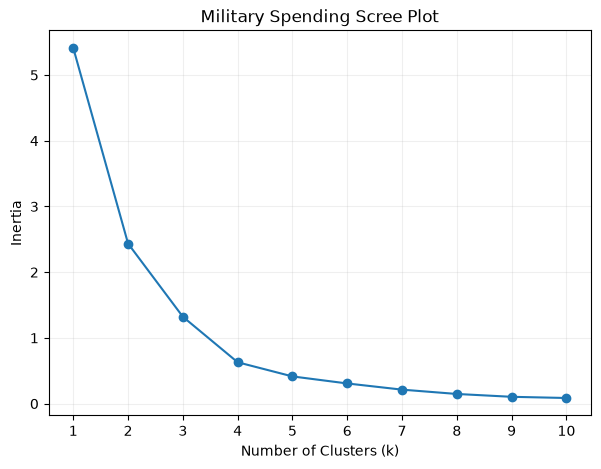

In [50]:
cols1 = [
    "Spending (2020 USD)",
    "Spending per Capita"
]

scaler = MinMaxScaler()

X1_new = scaler.fit_transform(df2[cols1])

scree_plot(X1_new, "Military Spending Scree Plot")

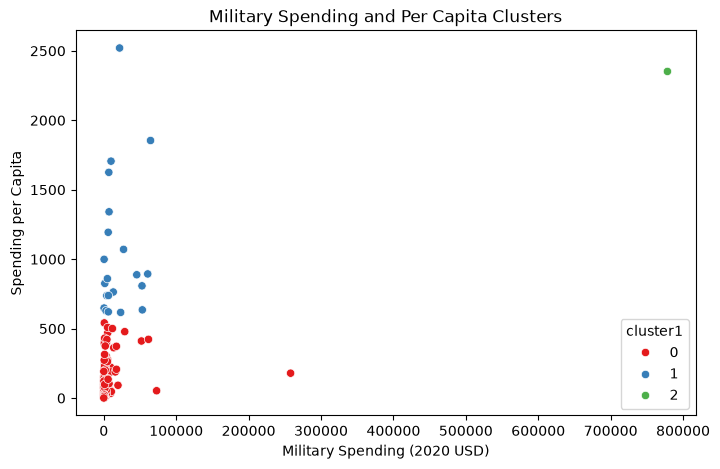

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster1                                                                   
0                      126.0    5943.346303  24858.961064       8.622460   
1                       21.0   19975.991473  21749.736747     405.790494   
2                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster1                                                               
0            162.761743     580.758315    3225.333414  257973.429834   
1           4980.428135    7269.880030   27300.894701   64558.400000   
2         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita                                        \
                       count         mea

In [51]:
k1 = 3

model1 = KMeans(
    n_clusters=k1,
    random_state=42,
    n_init=10
)

df2["cluster1"] = model1.fit_predict(X1_new)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df2,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster1",
    palette="Set1"
)

plt.title("Military Spending and Per Capita Clusters")
plt.xlabel("Military Spending (2020 USD)")
plt.ylabel("Spending per Capita")
plt.show()

print(df2.groupby("cluster1")[cols1].describe())

print("\nUnited States:")
print(
    df2[df2["Country"] == "United States"][
        ["Country", "cluster1"] + cols1
    ]
)

print("\nCountries in each cluster:")
print(df2.groupby("cluster1")["Country"].apply(list))

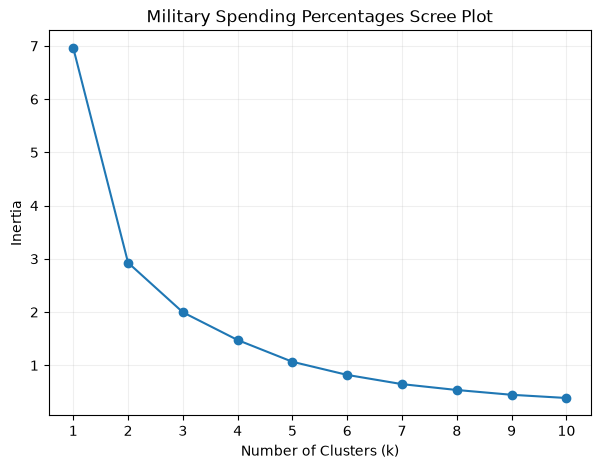

In [52]:
cols2 = [
    "Percent of Government Spending",
    "Percent of GDP"
]

X2_new = scaler.fit_transform(df2[cols2])

scree_plot(X2_new, "Military Spending Percentages Scree Plot")

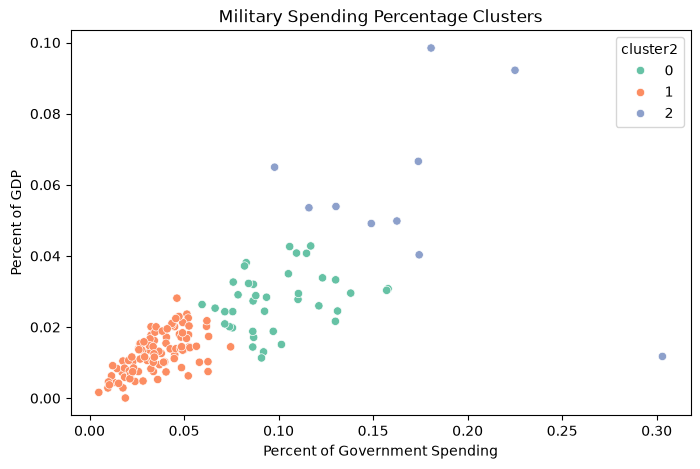

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  99.0  0.035777  0.014549  0.004896   
2                                  10.0  0.171289  0.058725  0.097882   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                      
               std       mi

In [53]:
k2 = 3

model2 = KMeans(
    n_clusters=k2,
    random_state=42,
    n_init=10
)

df2["cluster2"] = model2.fit_predict(X2_new)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df2,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster2",
    palette="Set2"
)

plt.title("Military Spending Percentage Clusters")
plt.xlabel("Percent of Government Spending")
plt.ylabel("Percent of GDP")
plt.show()

print(df2.groupby("cluster2")[cols2].describe())

print("\nUnited States:")
print(
    df2[df2["Country"] == "United States"][
        ["Country", "cluster2"] + cols2
    ]
)

print("\nCountries in each cluster:")
print(df2.groupby("cluster2")["Country"].apply(list))

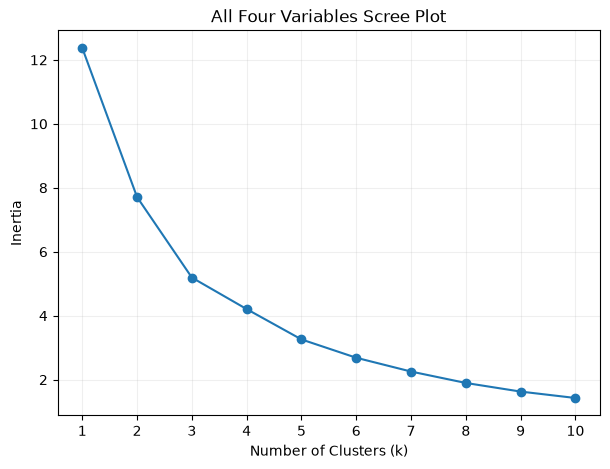

In [54]:
cols3 = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

X3_new = scaler.fit_transform(df2[cols3])

scree_plot(X3_new, "All Four Variables Scree Plot")

In [55]:
k3 = 3

model3 = KMeans(
    n_clusters=k3,
    random_state=42,
    n_init=10
)

df2["cluster3"] = model3.fit_predict(X3_new)

print("Cluster sizes:")
print(df2["cluster3"].value_counts())

print("\nCluster statistics:")
print(df2.groupby("cluster3")[cols3].describe())

print("\nCountries in each cluster:")
print(df2.groupby("cluster3")["Country"].apply(list))

Cluster sizes:
cluster3
2    111
0     31
1      6
Name: count, dtype: int64

Cluster statistics:
         Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster3                                                                  
0                       31.0    8786.086602   17901.909108   162.373364   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                      111.0    7086.472777   26479.379918     8.622460   

                                                                  \
                  25%           50%           75%            max   
cluster3                                                           
0          467.787851   1404.787234   7739.166193   72937.064048   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          130.010211    567.650747   3910.107493  257973.429834   

         Spending per Capita              

In [56]:
print("Part 2 vs Part 3")
print(pd.crosstab(df2["cluster1"], df2["cluster2"]))

print("\nPart 2 vs Part 4")
print(pd.crosstab(df2["cluster1"], df2["cluster3"]))

print("\nPart 3 vs Part 4")
print(pd.crosstab(df2["cluster2"], df2["cluster3"]))

Part 2 vs Part 3
cluster2   0   1  2
cluster1           
0         34  86  6
1          4  13  4
2          1   0  0

Part 2 vs Part 4
cluster3   0  1   2
cluster1           
0         28  0  98
1          3  5  13
2          0  1   0

Part 3 vs Part 4
cluster3   0  1   2
cluster2           
0         25  2  12
1          0  0  99
2          6  4   0


### Q2: Military Expenditure Clustering

The results show how countries can be grouped differently depending on which military spending variables are used.

In the first analysis, countries are grouped based on total military spending and spending per capita. In the second analysis, countries are grouped based on military spending as a percentage of government spending and GDP.

These results can be different because a country might spend a lot of money on its military overall but still spend a relatively small percentage of its GDP.

Using all four variables gives a broader comparison because it considers both total spending and spending percentages. However, including more variables can also change which countries are grouped together.

I think K-Means is useful because it helps identify countries with similar military spending patterns. One limitation is that it cannot explain why countries spend different amounts. Also, unusual countries with very high spending can influence the clusters.

### *Reflection on AI assistance
In your own words without generative AI.

Overall, I think using AI helped improve my assignment in a few different ways. One of the these things was that it made my code shorter and better organized. In Phase 1, I seemed to have repeated a lot of the same code to create scatterplots and scree plots. AI says I should be using loops and functions instead. It also helped my graphs by adding better labels and also combining the scree plots so I could compare the different noise levels.

One issue I noticed was that AI originally suggested using k = 3 for the clustering analyses without actually checking the scree plots. I learned that I should not automatically assume AI suggestions are correct and need to look at the results myself.

To verify the changes I ran the updated code and checked that the graphs and tables appeared correctly. I also checked the missing values and the number of countries in the dataset. Comparing the results with Phase 1 helped me see what changed.

One concern I still have is that choosing the correct number of clusters is not always easy. This is especially when the elbow is unclear. Also, K-Means can identify similarities between countries, but it cannot explain why their military spending differs.